# IT594 Project: Notebook 04, constraint-aware reranking on WANDS

**Idea:** take each system's top 100 and push down products whose **color field contradicts the query's color**.
Products with a missing or multicolor color are never penalized.

**Compared against:** the unchanged systems, and a **hard color filter** (keep only products whose color field matches).

**Reported separately, as always:** relevance (NDCG@10) and color violation.

**Honesty check:** the reranker's signal (color field only) is close to the grader (checker v2.1), so a drop in violations is
partly built in. The independent evidence is NDCG: the relevance labels know nothing about the checker.
Section 7 exports a held-out sample for a human check.

## 1. Setup and load data

In [1]:
import os, re, sys
import numpy as np, pandas as pd

sys.path.insert(0, "../src")
from metrics import ndcg_at_k, constraint_violation_rate, paired_bootstrap
from color_checker import query_colors, color_check
from retrieval import rrf
from rerank import field_violates, field_matches, demote, hard_filter

PATH = "../data/WANDS/dataset/"
products = pd.read_csv(PATH + "product.csv", sep="\t")
queries  = pd.read_csv(PATH + "query.csv",   sep="\t")
labels   = pd.read_csv(PATH + "label.csv",   sep="\t")

GAIN = {"Exact": 2, "Partial": 1, "Irrelevant": 0}
labels["gain"] = labels["label"].map(GAIN)
qrels = {q: dict(zip(g["product_id"], g["gain"])) for q, g in labels.groupby("query_id")}
qtext = dict(zip(queries["query_id"], queries["query"]))
all_q = list(queries["query_id"])

def parse_features(s):
    d = {}
    if pd.isna(s):
        return d
    for pair in s.split("|"):
        if ":" in pair:
            k, v = pair.split(":", 1)
            d[k.strip().lower()] = v.strip()
    return d

feat = products["product_features"].apply(parse_features)
pcolor = dict(zip(products["product_id"], feat.apply(lambda d: d.get("color") or d.get("primarycolor") or "")))

for c in ["product_name", "product_class", "product_description"]:
    products[c] = products[c].fillna("")
pname = dict(zip(products["product_id"], products["product_name"]))
print(products.shape, queries.shape, labels.shape)

(42994, 9) (480, 3) (233448, 5)


## 2. Base runs: BM25, dense, hybrid (same as `eval.ipynb`)

In [2]:
from rank_bm25 import BM25Okapi

products["text"] = products["product_name"] + ". " + products["product_class"] + ". " + products["product_description"].str.slice(0, 500)
pids = products["product_id"].values

tok = lambda s: re.findall(r"[a-z0-9]+", s.lower())
bm25 = BM25Okapi([tok(t) for t in products["text"]])
runs = {"bm25": {q: list(pids[np.argsort(-bm25.get_scores(tok(qtext[q])))[:100]]) for q in all_q}}
print("bm25 done")

bm25 done


In [3]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
EMB = "wands_emb.npy"     # same cache file as notebook 03 and eval.ipynb
if os.path.exists(EMB):
    E = np.load(EMB)
else:
    E = model.encode(products["text"].tolist(), batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    np.save(EMB, E)

Qe = model.encode([qtext[q] for q in all_q], normalize_embeddings=True)
S = Qe @ E.T
runs["dense"] = {q: list(pids[np.argsort(-S[i])[:100]]) for i, q in enumerate(all_q)}
runs["hybrid_rrf"] = {q: rrf([runs["bm25"][q], runs["dense"][q]]) for q in all_q}
print({name: len(r) for name, r in runs.items()})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

{'bm25': 480, 'dense': 480, 'hybrid_rrf': 480}


## 3. The reranker's signal vs the grader

The **signal** (used to rerank) reads only the color field: no title fallback, no typo tolerance, never penalizes missing or multicolor.
The **grader** (used to score) is checker v2.1. This table shows how often they agree on the base top 10, so the overlap is visible.

In [4]:
K = 10
LENIENT = True
color_qids = [q for q in all_q if query_colors(qtext[q], LENIENT)]
print("queries naming a color:", len(color_qids))

def grader(qid):
    qcols = query_colors(qtext[qid], LENIENT)
    return lambda p: color_check(qcols, pcolor.get(p, ""), pname.get(p, ""), LENIENT)

def signal(qid):
    qcols = query_colors(qtext[qid], LENIENT)
    return lambda p: field_violates(qcols, pcolor.get(p, ""), LENIENT)

rows = []
for n, r in runs.items():
    for q in color_qids:
        g, s = grader(q), signal(q)
        rows += [{"system": n, "signal_flags": s(p), "grader": g(p)} for p in r[q][:K]]
pd.crosstab([pd.DataFrame(rows)["system"], pd.DataFrame(rows)["signal_flags"]], pd.DataFrame(rows)["grader"])

queries naming a color: 44


grader                   ambiguous  match  mismatch  unknown
system     signal_flags                                     
bm25       False                 0    183         6      171
           True                  0      0        80        0
dense      False                 3    116        19      179
           True                  0      0       123        0
hybrid_rrf False                 1    155        15      187
           True                  0      0        82        0

## 4. Penalty sweep

`demote` moves each flagged product **penalty** positions down; `inf` moves it to the end of the top 100.
Relevance and violation are in **separate tables** (color queries only; other queries are never changed).

In [5]:
PENALTIES = [0, 1, 2, 3, 5, 10, 20, float("inf")]

def rerank(run, qids, penalty):
    return {q: demote(run[q], signal(q), penalty) for q in qids}

def ndcg_per_query(run, qids):
    return [ndcg_at_k(run[q], qrels.get(q, {}), K) for q in qids]

def viol_per_query(run, qids, among="checkable"):
    return [constraint_violation_rate(run[q], grader(q), K, among) for q in qids]

sweep = {(n, lam): rerank(r, color_qids, lam) for n, r in runs.items() for lam in PENALTIES}

rel_sweep = pd.DataFrame({lam: {n: np.mean(ndcg_per_query(sweep[n, lam], color_qids)) for n in runs} for lam in PENALTIES})
viol_sweep = pd.DataFrame({lam: {n: np.nanmean(viol_per_query(sweep[n, lam], color_qids)) for n in runs} for lam in PENALTIES})
rel_sweep.columns.name = viol_sweep.columns.name = "penalty"
print("Relevance: NDCG@10 on color queries")
display(rel_sweep.round(3))
print("Constraint: violation rate (checkable) on color queries")
display(viol_sweep.round(3))

Relevance: NDCG@10 on color queries


penalty,0.0,1.0,2.0,3.0,5.0,10.0,20.0,inf
bm25,0.533,0.536,0.538,0.538,0.540,0.535,0.536,0.538
dense,0.560,0.565,0.566,0.571,0.573,0.574,0.570,0.566
hybrid_rrf,0.644,0.647,0.645,0.646,0.643,0.641,0.632,0.630


Constraint: violation rate (checkable) on color queries


penalty,0.0,1.0,2.0,3.0,5.0,10.0,20.0,inf
bm25,0.316,0.301,0.298,0.285,0.269,0.182,0.092,0.065
dense,0.592,0.572,0.563,0.527,0.493,0.424,0.259,0.166
hybrid_rrf,0.416,0.408,0.378,0.368,0.332,0.257,0.175,0.134


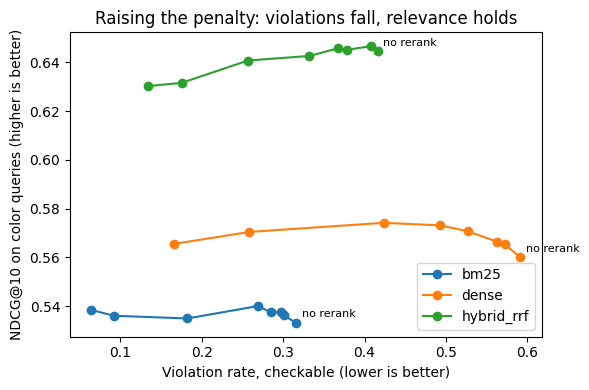

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for n in runs:
    ax.plot(viol_sweep.loc[n], rel_sweep.loc[n], marker="o", label=n)
    ax.annotate("no rerank", (viol_sweep.loc[n, 0], rel_sweep.loc[n, 0]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Violation rate, checkable (lower is better)")
ax.set_ylabel("NDCG@10 on color queries (higher is better)")
ax.set_title("Raising the penalty: violations fall, relevance holds")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Choosing the penalty without peeking: 2-fold cross-validation

Rule: on the tuning half, keep penalties whose NDCG is at most **0.01 below** the unchanged system's (smaller than the noise: the
bootstrap intervals are about ±0.02 wide), then take the one with the **lowest violation rate** (ties: the smaller penalty).
Report it on the **other half**, which it never saw; then swap halves.

The 0.01 tolerance was set while developing this notebook on a test run with a stand-in for dense, before the real dense results;
a zero tolerance rejected every penalty over drops as small as 0.003.

In [7]:
rng = np.random.default_rng(0)
shuffled = list(rng.permutation(color_qids))
folds = [shuffled[0::2], shuffled[1::2]]

TOL = 0.01

def choose_penalty(n, qids):
    base = np.mean(ndcg_per_query(sweep[n, 0], qids))
    ok = [lam for lam in PENALTIES if np.mean(ndcg_per_query(sweep[n, lam], qids)) >= base - TOL]
    return min(ok, key=lambda lam: (np.nanmean(viol_per_query(sweep[n, lam], qids)), lam))

chosen = {}
for n in runs:
    picks = [choose_penalty(n, folds[i]) for i in (0, 1)]
    chosen[n] = picks
    print(f"{n:10s}: tuned on half A -> {picks[0]},  tuned on half B -> {picks[1]}")

# held-out run: each query reranked with the penalty chosen on the OTHER half
held_out = {n: {**{q: sweep[n, chosen[n][1]][q] for q in folds[0]},
                **{q: sweep[n, chosen[n][0]][q] for q in folds[1]}} for n in runs}

bm25      : tuned on half A -> inf,  tuned on half B -> inf
dense     : tuned on half A -> inf,  tuned on half B -> inf
hybrid_rrf: tuned on half A -> inf,  tuned on half B -> 5


## 6. Final comparison (held-out penalties)

`+rerank` = held-out penalty from section 5. `+hard filter` = keep only products whose color field names the query color.
Non-color queries are unchanged by every method, so all-query NDCG differences come only from the 44 color queries.
`top-10 judged share` = share of top-10 products with a relevance label; unlabeled ones count as 0 in NDCG, so a lower share makes NDCG a lower bound.

In [8]:
def filtered(run, qids):
    out = {}
    for q in qids:
        qcols = query_colors(qtext[q], LENIENT)
        out[q] = hard_filter(run[q], lambda p: field_matches(qcols, pcolor.get(p, ""), LENIENT))
    return out

def judged_share(run, qids):
    """Share of returned top-10 products that have a relevance label (queries with no results are skipped)."""
    return np.mean([np.mean([p in qrels.get(q, {}) for p in run[q][:K]]) for q in qids if run[q]])

methods = {}
for n, r in runs.items():
    methods[n] = r
    methods[n + " +rerank"]      = {**r, **held_out[n]}
    methods[n + " +hard filter"] = {**r, **filtered(r, color_qids)}

relevance = pd.DataFrame({
    "NDCG@10 (all 480)":       {m: np.mean(ndcg_per_query(r, all_q)) for m, r in methods.items()},
    "NDCG@10 (color queries)": {m: np.mean(ndcg_per_query(r, color_qids)) for m, r in methods.items()},
    "color queries with < 10 results": {m: sum(len(r[q]) < K for q in color_qids) for m, r in methods.items()},
    "top-10 judged share (color queries)": {m: judged_share(r, color_qids) for m, r in methods.items()},
})
constraint = pd.DataFrame({
    "violation_rate (checkable)": {m: np.nanmean(viol_per_query(r, color_qids)) for m, r in methods.items()},
    "violating share of top-10":  {m: np.mean(viol_per_query(r, color_qids, "k")) for m, r in methods.items()},
})
print("Relevance"); display(relevance.round(3))
print("Constraint"); display(constraint.round(3))

Relevance


,NDCG@10 (all 480),NDCG@10 (color queries),color queries with < 10 results,top-10 judged share (color queries)
bm25,0.687,0.533,0,0.675
bm25 +rerank,0.687,0.538,0,0.677
bm25 +hard filter,0.665,0.299,14,0.515
dense,0.697,0.560,0,0.673
dense +rerank,0.698,0.566,0,0.670
dense +hard filter,0.674,0.308,22,0.572
hybrid_rrf,0.748,0.644,0,0.789
hybrid_rrf +rerank,0.747,0.636,0,0.777
hybrid_rrf +hard filter,0.719,0.332,16,0.537


Constraint


,violation_rate (checkable),violating share of top-10
bm25,0.316,0.195
bm25 +rerank,0.065,0.020
bm25 +hard filter,0.000,0.000
dense,0.592,0.323
dense +rerank,0.166,0.050
dense +hard filter,0.000,0.000
hybrid_rrf,0.416,0.220
hybrid_rrf +rerank,0.238,0.111
hybrid_rrf +hard filter,0.000,0.000


In [9]:
PAIRS = [("bm25 +rerank", "bm25"), ("dense +rerank", "dense"), ("hybrid_rrf +rerank", "hybrid_rrf"),
         ("hybrid_rrf +rerank", "bm25"), ("hybrid_rrf +rerank", "hybrid_rrf +hard filter")]

print("Relevance: NDCG@10 difference on color queries")
for a, b in PAIRS:
    m, (lo, hi), n = paired_bootstrap(ndcg_per_query(methods[a], color_qids), ndcg_per_query(methods[b], color_qids))
    print(f"  {a:20s} - {b:24s}: {m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  (n={n})")

print("\nConstraint: violation-rate difference on color queries")
for a, b in PAIRS:
    m, (lo, hi), n = paired_bootstrap(viol_per_query(methods[a], color_qids), viol_per_query(methods[b], color_qids))
    print(f"  {a:20s} - {b:24s}: {m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  (n={n})")

Relevance: NDCG@10 difference on color queries
  bm25 +rerank         - bm25                    : +0.005  95% CI [-0.019, +0.031]  (n=44)
  dense +rerank        - dense                   : +0.006  95% CI [-0.015, +0.025]  (n=44)
  hybrid_rrf +rerank   - hybrid_rrf              : -0.009  95% CI [-0.024, +0.004]  (n=44)
  hybrid_rrf +rerank   - bm25                    : +0.103  95% CI [+0.060, +0.147]  (n=44)
  hybrid_rrf +rerank   - hybrid_rrf +hard filter : +0.304  95% CI [+0.199, +0.409]  (n=44)

Constraint: violation-rate difference on color queries
  bm25 +rerank         - bm25                    : -0.252  95% CI [-0.340, -0.172]  (n=40)
  dense +rerank        - dense                   : -0.413  95% CI [-0.524, -0.313]  (n=35)
  hybrid_rrf +rerank   - hybrid_rrf              : -0.178  95% CI [-0.256, -0.109]  (n=38)
  hybrid_rrf +rerank   - bm25                    : -0.106  95% CI [-0.194, -0.027]  (n=37)
  hybrid_rrf +rerank   - hybrid_rrf +hard filter : +0.218  95% CI [+0.135, +0.

## 7. Human check of what the reranker moved

The grader and the signal overlap, so check by hand: of the products the reranker pushed **out** of hybrid's top 10, how many are truly the
wrong color? Fill `my_verdict` with `real` / `shade` / `metadata` / `checker` (same meanings as `eval.ipynb`).

In [10]:
MOVED = "../results/rerank_moved_check.csv"
if os.path.exists(MOVED):
    print("Already exported; not overwriting.")
else:
    rows = []
    for q in color_qids:
        before, after = runs["hybrid_rrf"][q][:K], methods["hybrid_rrf +rerank"][q][:K]
        for p in before:
            if p not in after:
                rows.append({"query": qtext[q], "product": pname[p][:70], "color_field": pcolor[p],
                             "label": {2: "Exact", 1: "Partial", 0: "Irrelevant"}.get(qrels.get(q, {}).get(p), "unjudged")})
    moved = pd.DataFrame(rows)
    if moved.empty:
        raise SystemExit("The reranker moved nothing out of hybrid's top 10; nothing to check.")
    sample = moved.sample(min(20, len(moved)), random_state=0)
    sample["my_verdict"] = ""
    sample.to_csv(MOVED, index=False)
    print(f"{len(moved)} products moved out of hybrid's top 10; saved {len(sample)} to {MOVED}")

51 products moved out of hybrid's top 10; saved 20 to ../results/rerank_moved_check.csv
